In [1]:
from pathlib import Path
import pandas as pd
filename = "Telco-Customer-Churn.csv"
candidates = [
    Path("data/raw") / filename,
    Path("../data/raw") / filename,
]
csv_path = next((path for path in candidates if path.exists()), None)

if csv_path is None:
    raise FileNotFoundError(f"没找到数据文件；Notebook 当前目录是：{Path.cwd()}")

df = pd.read_csv(csv_path)

print("读取文件：", csv_path.resolve())
print("数据形状：", df.shape)
display(df.head())

读取文件： C:\Users\27772\Desktop\telco-churn-analysis\data\raw\Telco-Customer-Churn.csv
数据形状： (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
print("流失标签数量：")
display(df["Churn"].value_counts(dropna=False))

print("流失标签比例（%）：")
display((df["Churn"].value_counts(normalize=True, dropna=False) * 100).round(1))

流失标签数量：


Churn
No     5174
Yes    1869
Name: count, dtype: int64

流失标签比例（%）：


Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64

In [4]:
print("缺失值最多的列：")
display(df.isna().sum().sort_values(ascending=False).head(10))

print("重复行数：", df.duplicated().sum())

缺失值最多的列：


customerID         0
gender             0
SeniorCitizen      0
Partner            0
Dependents         0
tenure             0
PhoneService       0
MultipleLines      0
InternetService    0
OnlineSecurity     0
dtype: int64

重复行数： 0


In [ ]:
print("Churn 标签数量：")
display(df["Churn"].value_counts(dropna=False))

print("Churn 标签比例（%）：")
display((df["Churn"].value_counts(normalize=True, dropna=False) * 100).round(1))

total_num = pd.to_numeric(df["TotalCharges"].str.strip(), errors="coerce")
bad_mask = total_num.isna()

print("TotalCharges 无法转为数值的行数：", int(bad_mask.sum()))
display(df.loc[bad_mask, ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]])


Churn 标签数量：


Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn 标签比例（%）：


Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64

TotalCharges 无法转为数值的行数： 11


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


流失标签不均衡：流失客户占 26.5%，未流失客户占 73.5%。如果模型把所有客户都预测为“未流失”，准确率也会有 73.5%；所以后续不能只看准确率，还要比较召回率、精确率等指标。
TotalCharges 有 11 个空白值：它们都对应 tenure = 0、`Churn = No`。因为空字符串不一定会被 info() 当成缺失值，后续清洗时要明确记录处理方式；现在先不要替换或删除。

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: churn_flag, dtype: float64

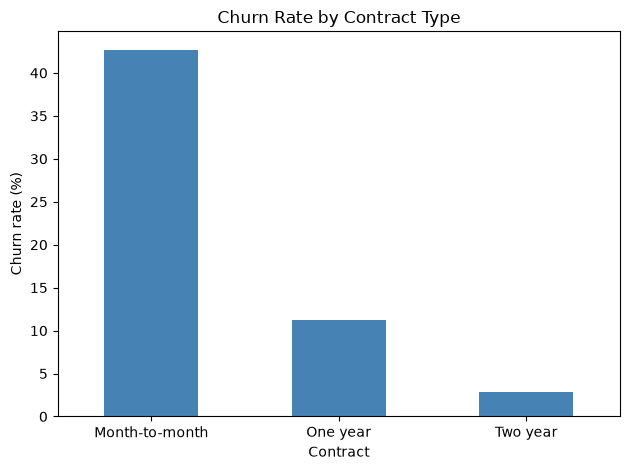

In [6]:
import matplotlib.pyplot as plt

churn_by_contract = (
    df.assign(churn_flag=df["Churn"].eq("Yes"))
      .groupby("Contract")["churn_flag"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

display(churn_by_contract.round(1))

ax = churn_by_contract.plot(kind="bar", color="steelblue")
ax.set_title("Churn Rate by Contract Type")
ax.set_xlabel("Contract")
ax.set_ylabel("Churn rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
display(pd.crosstab(df["Contract"], df["Churn"], margins=True))

Churn,No,Yes,All
Contract,,,
Month-to-month,2220,1655,3875
One year,1307,166,1473
Two year,1647,48,1695
All,5174,1869,7043


Churn,No,Yes
tenure,,
0–12,52.6,47.4
13–24,71.3,28.7
25–48,79.6,20.4
49–72,90.5,9.5


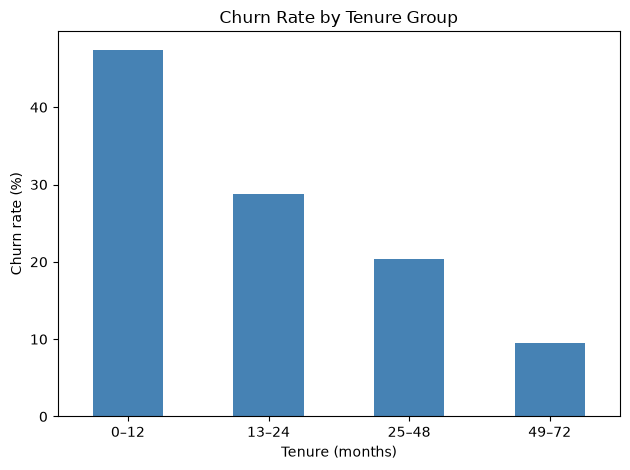

In [8]:
tenure_group = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0–12", "13–24", "25–48", "49–72"]
)

tenure_churn = pd.crosstab(
    tenure_group,
    df["Churn"],
    normalize="index"
).mul(100)

display(tenure_churn.round(1))

ax = tenure_churn["Yes"].plot(kind="bar", color="steelblue")
ax.set_title("Churn Rate by Tenure Group")
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Churn rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

合同类型：月付合同流失率最高，为 42.7%；一年合同为 11.3%，两年合同为 2.8%。月付组流失客户有 1,655 人，但这是组内的关联，不足以说明合同类型导致流失。
在网时长：流失率从 0–12 个月的 47.4%，逐段降至 49–72 个月的 9.5%。可以描述为“样本中，在网时长越长，流失比例越低”；这也不代表因果关系。

In [9]:
monthly_summary = df.groupby("Churn").agg(
    customer_count=("MonthlyCharges", "size"),
    mean_monthly_charge=("MonthlyCharges", "mean"),
    median_monthly_charge=("MonthlyCharges", "median")
).round(2)

display(monthly_summary)

,customer_count,mean_monthly_charge,median_monthly_charge
Churn,,,
No,5174,61.27,64.43
Yes,1869,74.44,79.65


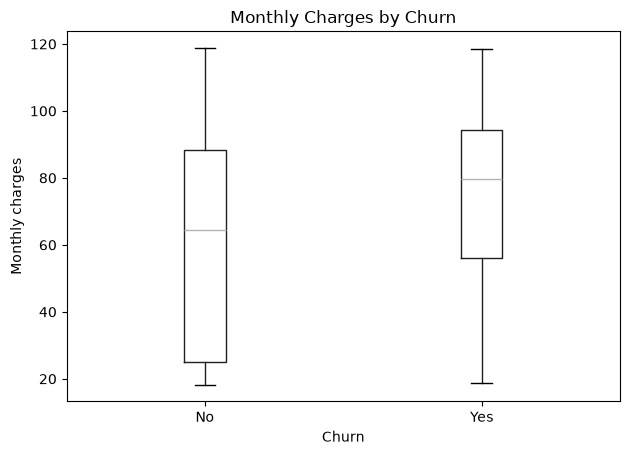

In [10]:
ax = df.boxplot(column="MonthlyCharges", by="Churn", grid=False)
plt.suptitle("")
plt.title("Monthly Charges by Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly charges")
plt.tight_layout()
plt.show()

- 流失客户的月费中位数为 79.65，未流失客户为 64.43；两组分布有较大重叠，月费单独不能区分所有流失客户。

In [11]:
print("重复行数：", df.duplicated().sum())
print("重复 customerID 数：", df["customerID"].duplicated().sum())

for column in ["Contract", "InternetService", "PaymentMethod", "Churn"]:
    print(f"\n{column} 的取值：")
    display(df[column].value_counts(dropna=False))

重复行数： 0
重复 customerID 数： 0

Contract 的取值：


Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64


InternetService 的取值：


InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64


PaymentMethod 的取值：


PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64


Churn 的取值：


Churn
No     5174
Yes    1869
Name: count, dtype: int64